In [21]:
%pip install "gymnasium" "numpy" "matplotlib" "pygame"

Note: you may need to restart the kernel to use updated packages.


Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\luiza\anaconda3\Lib\site-packages\pip\__main__.py", line 24, in <module>
    sys.exit(_main())
             ^^^^^^^
  File "c:\Users\luiza\anaconda3\Lib\site-packages\pip\_internal\cli\main.py", line 78, in main
    command = create_command(cmd_name, isolated=("--isolated" in cmd_args))
              ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\luiza\anaconda3\Lib\site-packages\pip\_internal\commands\__init__.py", line 114, in create_command
    module = importlib.import_module(module_path)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\luiza\anaconda3\Lib\importlib\__init__.py", line 90, in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>", line 138

In [22]:
import gymnasium as gym
import heapq
import os
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env
import matplotlib.pyplot as plt
os.environ.setdefault("PYGAME_HIDE_SUPPORT_PROMPT", "1")
import pygame
import numpy as np
from IPython.display import Image
import time

## Objetivo principal do agente

O agente deve concluir a sequencia de escape no ambiente simulado:

1. Soltar o cinto de seguranca.
2. Caminhar ate a cabine dos pilotos e apertar o botao de emergencia.
3. So depois do botao ser apertado, caminhar ate a unica saida traseira e abri-la.

Apertar o botao libera a saida; o agente nao pega nem carrega o botao.


## The layout do mapa

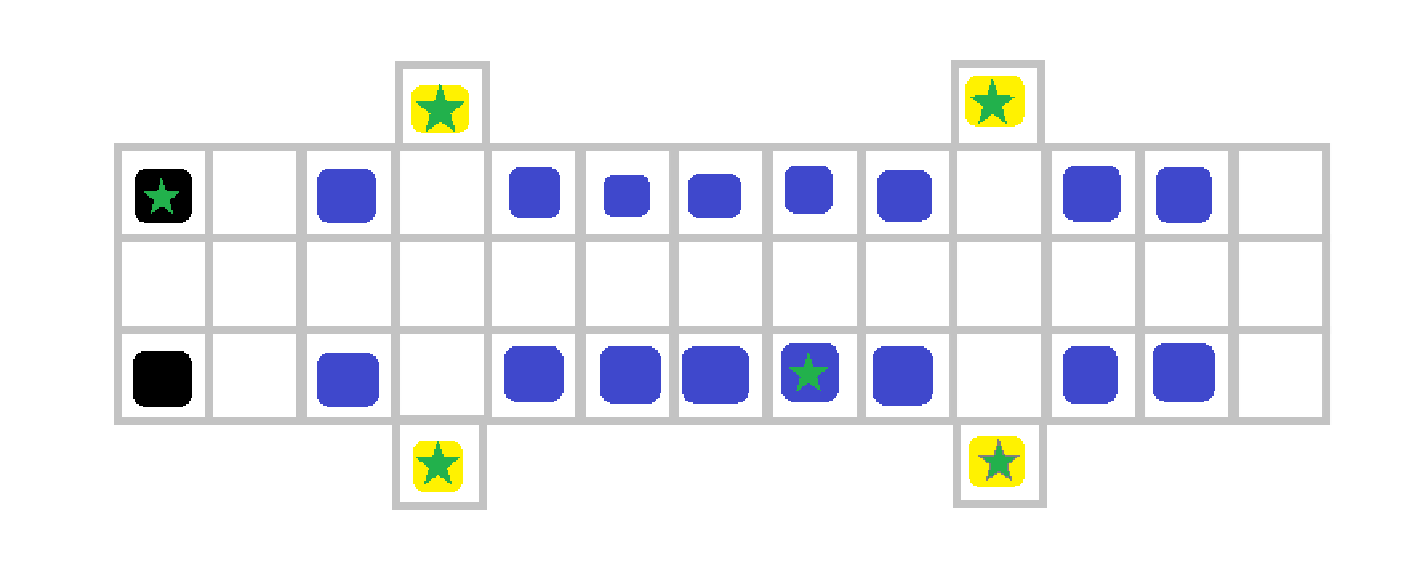

In [23]:
Image(filename='map.png', width=500, height=500)

1. Quadrado azul: assentos do aviao;  
2. Quadrado preto: assentos dos pilotos;  
3. Quadrado amarelo: saida;  
4. Botao amarelo: botao de emergencia interagivel;  

### Regras de movimento e interacao

1. Enquanto estiver preso pelo cinto, o agente quase nao consegue se mover: uma tentativa tem apenas 0,1% de chance de funcionar e recebe penalidade. `largar` solta o cinto, concede recompensa e a mudanca e permanente.
2. O aviao tem nove fileiras na configuracao 2-3-2, com corredores nas colunas 2 e 6.
3. O curriculo comeca com assento e malas fixos; depois varia as malas e, por fim, tambem o assento inicial. A partir da segunda fase, 40% dos episodios comecam com o cinto solto e a saida liberada para praticar a rota final.
4. A chance de atravessar um assento ocupado e constante em 20%; ela nao diminui conforme o agente cruza outros assentos.
5. Duas malas (`M`) aparecem nos corredores. Cada mala pode ser atravessada com 65% de chance por tentativa.
6. O limite de passos diminui progressivamente durante o treinamento; a avaliacao usa um limite mais curto.
7. O agente deve apertar o botao na cabine dos pilotos depois de soltar o cinto. Isso libera a saida, sem carregar um objeto.
8. A saida traseira nao pode ser alcancada nem aberta antes do botao ser apertado.

As coordenadas sao `(x, y)`, com `x` atravessando a cabine e `y` indo da frente para tras. A observacao inclui a posicao do agente, o estado do cinto, se a saida foi liberada, as duas malas e os passos restantes.

Durante o treinamento, a janela mostra episodios reais da exploracao. `TRAINING_ANIMATION_INTERVAL` controla o intervalo; o padrao anima episodios mais avancados para facilitar a visualizacao do aprendizado. Os indicadores na janela mostram, nos 100 episodios anteriores, a frequencia de retirada do cinto, acionamento do botao e chegada a saida.


In [24]:
class CabinEnv(gym.Env):
    metadata = {"render_modes": ["ansi", "human"], "render_fps": 8}

    ACTIONS = ("cima", "baixo", "esquerda", "direita", "apertar", "largar", "abrir")
    PILOT_POS = (4, 0)
    BUTTON_POS = (3, 0)
    EXIT_POSITIONS = {(4, 10)}
    REAR_EXITS = EXIT_POSITIONS
    SEAT_COLUMNS = (0, 1, 3, 4, 5, 7, 8)
    START_POSITIONS = tuple(
        (x, y)
        for y in range(1, 10)
        for x in (0, 1, 3, 4, 5, 7, 8)
    )
    BAG_CROSSING_PROBABILITY = 0.65
    BAG_ATTEMPT_PENALTY = 0.25
    OBSTACLE_CROSSING_PROBABILITY = 0.2
    OBSTACLE_ATTEMPT_PENALTY = 0.25
    NAVIGATION_SHAPING_SCALE = 0.5
    BELTED_ESCAPE_PROBABILITY = 0.001
    BELT_RELEASE_REWARD = 5.0
    BUTTON_PRESS_REWARD = 10.0
    BELT_ATTEMPT_PENALTY = 1.0
    BAG_ROWS = tuple(range(1, 10))
    MOVE_DELTAS = {
        0: (0, -1),
        1: (0, 1),
        2: (-1, 0),
        3: (1, 0),
    }

    def __init__(self, max_steps: int = 100, render_mode: str | None = None):
        super().__init__()
        if render_mode not in (None, "ansi", "human"):
            raise ValueError(f"render_mode invalido: {render_mode!r}")

        self.render_mode = render_mode
        self._pygame_screen = None
        self._pygame_font = None
        self._pygame_small_font = None
        self._window_closed = False
        self.training_episode: int | None = None
        self.training_epsilon = 0.0
        self.training_stage_rates = (0.0, 0.0, 0.0)
        self.max_steps = max_steps
        # Nove fileiras de assentos entre o cockpit e a unica saida traseira.
        self.height, self.width = 11, 9
        self.world_map = np.zeros((self.height, self.width), dtype=np.int8)
        # Fileiras de passageiros e corredores laterais.
        self.world_map[1:10, :] = 1
        # Na frente so existe o cockpit e o ponto do botao; atras, so a saida.
        self.world_map[0, self.BUTTON_POS[0]] = 1
        self.world_map[0, self.PILOT_POS[0]] = 1
        for x, y in self.EXIT_POSITIONS:
            self.world_map[y, x] = 1

        # Configuracao transversal 2-3-2; colunas 2 e 6 sao corredores.
        self.obstacles = {
            (x, y)
            for y in range(1, self.height - 1)
            for x in self.SEAT_COLUMNS
        }
        self.obstacle_crossings = len(self.obstacles)
        self._distance_maps: dict[tuple[object, ...], dict[tuple[int, int], float]] = {}
        self.action_space = spaces.Discrete(len(self.ACTIONS))
        self.observation_space = spaces.Box(
            low=np.array([0, 0, 0, 0, 0, 1, 0, 1, 0], dtype=np.int32),
            high=np.array([
                self.width - 1,
                self.height - 1,
                1,
                1,
                self.width - 1,
                self.height - 2,
                self.width - 1,
                self.height - 2,
                self.max_steps,
            ], dtype=np.int32),
            dtype=np.int32,
        )
        self.reset()

    def _get_obs(self) -> np.ndarray:
        (bag1_x, bag1_y), (bag2_x, bag2_y) = sorted(self.bag_positions)
        return np.array([
            self.agent_pos[0],
            self.agent_pos[1],
            int(not self.belt_fastened),
            int(self.exit_unlocked),
            bag1_x,
            bag1_y,
            bag2_x,
            bag2_y,
            self.episode_max_steps - self.steps,
        ], dtype=np.int32)

    def available_actions(self) -> tuple[int, ...]:
        if self.belt_fastened:
            return (5,)

        position = tuple(int(value) for value in self.agent_pos)
        actions = []
        for action, (dx, dy) in self.MOVE_DELTAS.items():
            target = (position[0] + dx, position[1] + dy)
            if self._is_walkable(target) and not (
                target in self.EXIT_POSITIONS and not self.exit_unlocked
            ):
                actions.append(action)
        if position == self.BUTTON_POS and not self.exit_unlocked:
            actions.append(4)
        if position in self.EXIT_POSITIONS and self.exit_unlocked:
            actions.append(6)
        return tuple(actions)

    def _is_walkable(self, position: tuple[int, int]) -> bool:
        x, y = position
        return (
            0 <= x < self.width
            and 0 <= y < self.height
            and self.world_map[y, x] == 1
        )

    def _navigation_distance(self) -> float | None:
        if self.exit_unlocked:
            targets = self.EXIT_POSITIONS
        elif not self.belt_fastened:
            targets = {self.BUTTON_POS}
        else:
            return None

        start = tuple(int(value) for value in self.agent_pos)
        cache_key = (tuple(sorted(self.bag_positions)), tuple(sorted(targets)))
        if cache_key not in self._distance_maps:
            distances = {target: 0.0 for target in targets}
            frontier = [(0.0, target) for target in targets]
            heapq.heapify(frontier)

            while frontier:
                distance, position = heapq.heappop(frontier)
                if distance != distances.get(position):
                    continue

                if position in self.bag_positions:
                    tile_cost = 1.0 / self.BAG_CROSSING_PROBABILITY
                elif position in self.obstacles:
                    tile_cost = 1.0 / self.OBSTACLE_CROSSING_PROBABILITY
                else:
                    tile_cost = 1.0

                x, y = position
                for dx, dy in self.MOVE_DELTAS.values():
                    previous = (x + dx, y + dy)
                    if not self._is_walkable(previous):
                        continue
                    candidate = distance + tile_cost
                    if candidate < distances.get(previous, float("inf")):
                        distances[previous] = candidate
                        heapq.heappush(frontier, (candidate, previous))

            self._distance_maps[cache_key] = distances

        return self._distance_maps[cache_key].get(start, float("inf"))

    def reset(
        self,
        *,
        seed: int | None = None,
        options: dict[str, object] | None = None,
    ) -> tuple[np.ndarray, dict[str, object]]:
        super().reset(seed=seed)
        options = options or {}

        start_pos = options.get("start_pos")
        if start_pos is None:
            start_pos = self.START_POSITIONS[int(self.np_random.integers(len(self.START_POSITIONS)))]
        start_pos = tuple(int(value) for value in start_pos)
        if start_pos not in self.START_POSITIONS:
            raise ValueError(f"Posicao inicial invalida: {start_pos!r}")

        bag_positions = options.get("bag_positions")
        if bag_positions is None:
            left_bag_row = int(self.np_random.choice(self.BAG_ROWS))
            right_bag_row = int(self.np_random.choice(self.BAG_ROWS))
            bag_positions = ((2, left_bag_row), (6, right_bag_row))
        bag_positions = tuple(tuple(int(value) for value in pos) for pos in bag_positions)
        if (
            len(bag_positions) != 2
            or bag_positions[0][0] != 2
            or bag_positions[1][0] != 6
            or bag_positions[0][1] not in self.BAG_ROWS
            or bag_positions[1][1] not in self.BAG_ROWS
        ):
            raise ValueError("Use uma mala em cada corredor, entre as fileiras 1 e 9.")

        episode_max_steps = int(options.get("episode_max_steps", self.max_steps))
        if not 1 <= episode_max_steps <= self.max_steps:
            raise ValueError(
                f"episode_max_steps deve estar entre 1 e {self.max_steps}."
            )

        belt_fastened = options.get("belt_fastened", True)
        exit_unlocked = options.get("exit_unlocked", False)
        if not isinstance(belt_fastened, bool) or not isinstance(exit_unlocked, bool):
            raise ValueError("belt_fastened e exit_unlocked devem ser valores booleanos.")
        if exit_unlocked and belt_fastened:
            raise ValueError("A saida liberada exige que o cinto esteja solto.")

        self.agent_pos = np.array(start_pos, dtype=np.int32)
        self.episode_max_steps = episode_max_steps
        self.bag_positions = set(bag_positions)
        self.belt_fastened = belt_fastened
        self.exit_unlocked = exit_unlocked
        self.button_position: tuple[int, int] | None = self.BUTTON_POS
        self.obstacles_crossed = 0
        self.steps = 0
        return self._get_obs(), {
            "start_pos": start_pos,
            "bag_positions": tuple(sorted(self.bag_positions)),
            "episode_max_steps": self.episode_max_steps,
        }

    def step(
        self, action: int
    ) -> tuple[np.ndarray, float, bool, bool, dict[str, object]]:
        if not self.action_space.contains(action):
            raise ValueError(f"Acao fora do espaco valido: {action!r}")

        self.steps += 1
        reward = -0.05
        terminated = False
        info: dict[str, object] = {}
        old_distance = self._navigation_distance()

        if action in self.MOVE_DELTAS:
            dx, dy = self.MOVE_DELTAS[action]
            next_pos = (int(self.agent_pos[0]) + dx, int(self.agent_pos[1]) + dy)
            if not self._is_walkable(next_pos):
                reward -= 1.0
                info["invalid_move"] = True
            elif next_pos in self.EXIT_POSITIONS and not self.exit_unlocked:
                reward -= 1.5
                info["exit_locked"] = True
            elif self.belt_fastened:
                probability = self.BELTED_ESCAPE_PROBABILITY
                info["belted_escape_probability"] = probability
                reward -= self.BELT_ATTEMPT_PENALTY
                if self.np_random.random() < probability:
                    self.agent_pos[:] = next_pos
                    info["moved_while_belted"] = True
                else:
                    info["moved_while_belted"] = False
            elif next_pos in self.bag_positions:
                probability = self.BAG_CROSSING_PROBABILITY
                info["bag_crossing_probability"] = probability
                if self.np_random.random() < probability:
                    self.agent_pos[:] = next_pos
                    reward -= 0.5
                    info["bag_crossed"] = True
                else:
                    reward -= self.BAG_ATTEMPT_PENALTY
                    info["bag_crossed"] = False
            elif next_pos in self.obstacles:
                probability = self.OBSTACLE_CROSSING_PROBABILITY
                info["obstacle_crossing_probability"] = probability
                if self.np_random.random() < probability:
                    self.agent_pos[:] = next_pos
                    self.obstacles_crossed = min(
                        self.obstacles_crossed + 1, self.obstacle_crossings
                    )
                    reward -= 0.25
                    info["obstacle_crossed"] = True
                else:
                    reward -= self.OBSTACLE_ATTEMPT_PENALTY
                    info["obstacle_crossed"] = False
            else:
                self.agent_pos[:] = next_pos

            if tuple(int(value) for value in self.agent_pos) in self.EXIT_POSITIONS:
                info["exit_reached"] = True
            new_distance = self._navigation_distance()
            if old_distance is not None and new_distance is not None:
                reward += self.NAVIGATION_SHAPING_SCALE * (old_distance - new_distance)

        elif action == 4:
            current_pos = tuple(int(value) for value in self.agent_pos)
            if self.belt_fastened:
                reward -= 1.5
            elif self.exit_unlocked:
                reward -= 1.0
                info["button_already_pressed"] = True
            elif current_pos == self.BUTTON_POS:
                self.exit_unlocked = True
                reward += self.BUTTON_PRESS_REWARD
                info["button_pressed"] = True
            else:
                reward -= 1.0

        elif action == 5:
            if self.belt_fastened:
                self.belt_fastened = False
                reward += self.BELT_RELEASE_REWARD
                info["belt_released"] = True
            else:
                reward -= 1.0
                info["belt_already_released"] = True

        elif action == 6:
            current_pos = tuple(int(value) for value in self.agent_pos)
            if (
                not self.belt_fastened
                and self.exit_unlocked
                and current_pos in self.EXIT_POSITIONS
            ):
                terminated = True
                reward += 100.0
                if current_pos in self.REAR_EXITS:
                    reward += 15.0
                info["success"] = True
                info["exit"] = "traseira" if current_pos in self.REAR_EXITS else "frontal"
            else:
                reward -= 1.5

        truncated = self.steps >= self.episode_max_steps and not terminated
        return self._get_obs(), reward, terminated, truncated, info

    def render(self) -> str | None:
        if self.render_mode is None:
            return None

        if self.render_mode == "ansi":
            grid = [
                ["." if self.world_map[y, x] else " " for x in range(self.width)]
                for y in range(self.height)
            ]
            for x, y in self.obstacles:
                grid[y][x] = "#"
            for x, y in self.EXIT_POSITIONS:
                grid[y][x] = "E"
            for x, y in self.bag_positions:
                grid[y][x] = "M"
            grid[self.PILOT_POS[1]][self.PILOT_POS[0]] = "P"
            if self.button_position is not None:
                bx, by = self.button_position
                grid[by][bx] = "b" if self.exit_unlocked else "B"
            x, y = (int(value) for value in self.agent_pos)
            grid[y][x] = "A"
            rows = [" ".join(row) for row in grid]
            rows.append(
                f"cinto={'preso' if self.belt_fastened else 'solto'} | "
                f"botao={'apertado' if self.exit_unlocked else 'pendente'} | "
                f"obstaculos={self.obstacles_crossed}/{self.obstacle_crossings} | "
                f"passos={self.steps}/{self.episode_max_steps}"
            )
            rows.append(
                f"Legenda: A agente, P cockpit, B botao, b apertado, # assento, "
                f"M mala ({self.BAG_CROSSING_PROBABILITY:.0%}), E saida"
            )
            rows.append("Assentos por fileira: ## . ### . ## (pontos sao corredores)")
            return "\n".join(rows)

        if self._window_closed:
            return None

        cell_size = 58
        margin = 44
        top = 104
        window_width = margin * 2 + self.width * cell_size
        window_height = top + self.height * cell_size + 44
        if self._pygame_screen is None:
            pygame.init()
            self._pygame_screen = pygame.display.set_mode((window_width, window_height))
            pygame.display.set_caption("CabinEnv - episodio do agente")
            self._pygame_font = pygame.font.Font(None, 28)
            self._pygame_small_font = pygame.font.Font(None, 21)

        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                self._window_closed = True
                self.close()
                return None

        screen = self._pygame_screen
        screen.fill((238, 242, 247))
        title_text = (
            f"Treino | episodio {self.training_episode} | "
            f"epsilon {self.training_epsilon:.2f}"
            if self.training_episode is not None
            else "Escape do aviao"
        )
        title = self._pygame_font.render(title_text, True, (28, 42, 58))
        screen.blit(title, (margin, 24))
        status = (
            f"Passo {self.steps}/{self.episode_max_steps}   "
            f"Cinto: {'preso' if self.belt_fastened else 'solto'}   "
            f"Botao: {'apertado' if self.exit_unlocked else 'pendente'}"
        )
        screen.blit(self._pygame_small_font.render(status, True, (48, 61, 76)), (margin, 62))
        belt_rate, button_rate, exit_rate = self.training_stage_rates
        progress = (
            f"Ultimos 100 episodios: cinto {belt_rate:.0%} | "
            f"botao {button_rate:.0%} | saida {exit_rate:.0%}"
        )
        screen.blit(self._pygame_small_font.render(progress, True, (48, 61, 76)), (margin, 82))

        aisle_color = (218, 226, 232)
        seat_color = (54, 91, 174)
        for y in range(self.height):
            for x in range(self.width):
                rect = pygame.Rect(
                    margin + x * cell_size + 3,
                    top + y * cell_size + 3,
                    cell_size - 6,
                    cell_size - 6,
                )
                position = (x, y)
                color = aisle_color if x in (2, 6) else (248, 249, 250)
                pygame.draw.rect(screen, color, rect, border_radius=8)
                if position in self.obstacles:
                    pygame.draw.rect(screen, seat_color, rect.inflate(-10, -8), border_radius=10)
                if position == self.PILOT_POS:
                    pygame.draw.rect(screen, (42, 48, 58), rect.inflate(-8, -8), border_radius=8)
                    label = self._pygame_small_font.render("P", True, (255, 255, 255))
                    screen.blit(label, label.get_rect(center=rect.center))
                if position in self.EXIT_POSITIONS:
                    pygame.draw.rect(screen, (42, 157, 105), rect.inflate(-8, -8), border_radius=8)
                    label = self._pygame_small_font.render("SAIDA", True, (255, 255, 255))
                    screen.blit(label, label.get_rect(center=rect.center))
                if position in self.bag_positions:
                    pygame.draw.rect(screen, (173, 105, 45), rect.inflate(-12, -14), border_radius=7)
                    label = self._pygame_font.render("M", True, (255, 255, 255))
                    screen.blit(label, label.get_rect(center=rect.center))
                if position == self.button_position:
                    pygame.draw.circle(screen, (237, 190, 48), rect.center, 18)
                    label = self._pygame_small_font.render("b" if self.exit_unlocked else "B", True, (45, 50, 55))
                    screen.blit(label, label.get_rect(center=rect.center))

        agent_x, agent_y = (int(value) for value in self.agent_pos)
        agent_center = (
            margin + agent_x * cell_size + cell_size // 2,
            top + agent_y * cell_size + cell_size // 2,
        )
        pygame.draw.circle(screen, (215, 54, 75), agent_center, 18)
        pygame.draw.circle(screen, (255, 255, 255), agent_center, 18, width=3)
        pygame.display.flip()
        return None

    @property
    def window_closed(self) -> bool:
        return self._window_closed

    def close(self) -> None:
        if self._pygame_screen is not None:
            pygame.display.quit()
            self._pygame_screen = None
            self._pygame_font = None
            self._pygame_small_font = None


Formato da observacao: (9,)
Acoes (0-6): ('cima', 'baixo', 'esquerda', 'direita', 'apertar', 'largar', 'abrir')
Treino visual ativado: um episodio a cada 2000 episodios.
Estados visitados: 76448
Sucesso na avaliacao: 75/100
Retorno medio na avaliacao: 105.95
Cinto solto: 100/100 episodios
Botao liberado: 92/100 episodios
Chegou a saida: 76/100 episodios
Escapou: 75/100 episodios


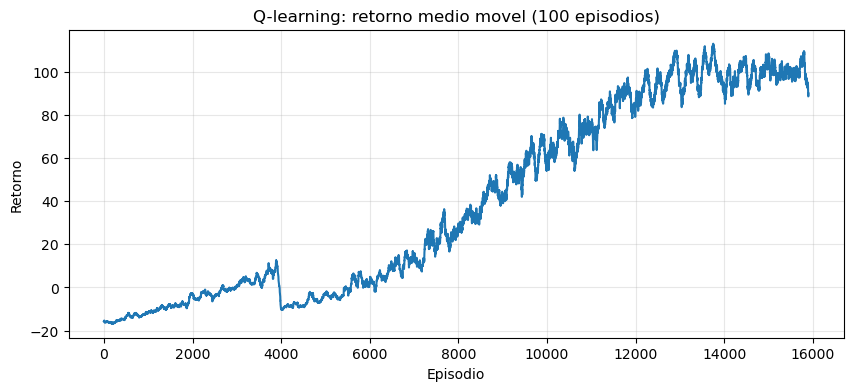

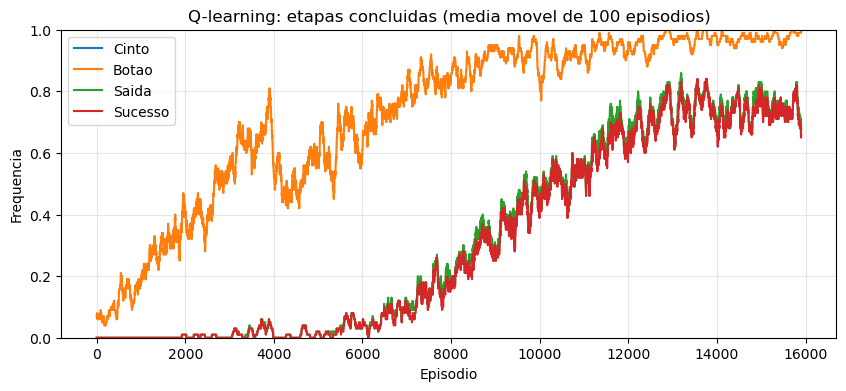

In [25]:
# Registra o ambiente para que o checker consiga testar os render_modes.
CABIN_ENV_ID = "CabinEnv-v0"
if CABIN_ENV_ID not in gym.registry:
    gym.register(id=CABIN_ENV_ID, entry_point=CabinEnv)

# Valida reset/step sem abrir janelas de teste antes do treinamento.
validation_env = gym.make(CABIN_ENV_ID)
try:
    check_env(validation_env.unwrapped, skip_render_check=True)
finally:
    validation_env.close()

# Renderiza episodios reais de treinamento, inclusive a evolucao da politica.
ANIMATE_TRAINING = True
TRAINING_ANIMATION_INTERVAL = 2000  # use 1 para animar cada episodio
ANIMATION_DELAY = 0.02  # segundos entre passos animados
if TRAINING_ANIMATION_INTERVAL < 1:
    raise ValueError("TRAINING_ANIMATION_INTERVAL deve ser pelo menos 1.")

env = CabinEnv(render_mode="human" if ANIMATE_TRAINING else "ansi")
obs, info = env.reset(seed=42)
print("Formato da observacao:", obs.shape)
print("Acoes (0-6):", CabinEnv.ACTIONS)
if not ANIMATE_TRAINING:
    print(env.render())
else:
    print(
        f"Treino visual ativado: um episodio a cada "
        f"{TRAINING_ANIMATION_INTERVAL} episodios."
    )

# O Q-learning usa estado compacto: posicao, cinto, botao, malas e tempo.
q_table: dict[tuple[int, ...], np.ndarray] = {}
rng = np.random.default_rng(42)
env.action_space.seed(42)
learning_rate = 0.15
discount = 0.95
num_episodes = 16000
EVALUATION_MAX_STEPS = 65
FIXED_START_POS = (4, 5)
FIXED_BAG_POSITIONS = ((2, 4), (6, 6))
CURRICULUM_FIXED_EPISODES = 4000
CURRICULUM_RANDOM_BAGS_EPISODE = 10000
EXIT_STAGE_TRAINING_FRACTION = 0.4

def training_deadline(episode: int) -> int:
    # Curriculo: encurta o prazo em etapas para manter o problema aprendivel.
    if episode < 2000:
        return 100
    if episode < 4000:
        return 90
    if episode < 6000:
        return 80
    if episode < 8000:
        return 70
    return EVALUATION_MAX_STEPS
training_returns = []
training_progress: list[tuple[bool, bool, bool, bool]] = []

def get_state_key(state: np.ndarray) -> tuple[int, ...]:
    values = tuple(int(value) for value in state)
    # Agrupa o relogio em blocos de cinco passos para reaproveitar experiencias.
    remaining_bucket = ((values[-1] + 4) // 5) * 5
    return values[:-1] + (remaining_bucket,)

def get_q_values(state: np.ndarray) -> np.ndarray:
    key = get_state_key(state)
    return q_table.setdefault(key, np.zeros(env.action_space.n, dtype=np.float64))

for episode in range(num_episodes):
    deadline = training_deadline(episode)
    reset_options: dict[str, object] = {"episode_max_steps": deadline}
    train_exit_stage = (
        episode >= CURRICULUM_FIXED_EPISODES
        and rng.random() < EXIT_STAGE_TRAINING_FRACTION
    )
    if train_exit_stage:
        reset_options.update({
            "start_pos": (3, 1),
            "belt_fastened": False,
            "exit_unlocked": True,
            "episode_max_steps": max(25, deadline - 25),
        })
    else:
        if episode < CURRICULUM_RANDOM_BAGS_EPISODE:
            reset_options["start_pos"] = FIXED_START_POS
        if episode < CURRICULUM_FIXED_EPISODES:
            reset_options["bag_positions"] = FIXED_BAG_POSITIONS
    state, _ = env.reset(seed=episode + 100, options=reset_options)
    epsilon = max(0.08, 1.0 - 0.92 * episode / 12000)
    episode_return = 0.0
    episode_belt_released = not env.belt_fastened
    episode_button_pressed = env.exit_unlocked
    episode_exit_reached = False
    animate_this_episode = (
        ANIMATE_TRAINING
        and episode > 0
        and episode % TRAINING_ANIMATION_INTERVAL == 0
        and not env.window_closed
    )
    if animate_this_episode:
        recent = training_progress[-100:]
        if recent:
            env.training_stage_rates = tuple(
                sum(row[index] for row in recent) / len(recent)
                for index in range(3)
            )
        env.training_episode = episode + 1
        env.training_epsilon = epsilon
        env.render()

    for _ in range(env.max_steps):
        q_values = get_q_values(state)
        available_actions = env.available_actions()
        if rng.random() < epsilon:
            action = int(rng.choice(available_actions))
        else:
            action_indices = np.array(available_actions, dtype=int)
            action = int(action_indices[np.argmax(
                q_values[action_indices] + rng.random(len(action_indices)) * 1e-8
            )])

        next_state, reward, terminated, truncated, step_info = env.step(action)
        episode_belt_released |= bool(step_info.get("belt_released", False))
        episode_button_pressed |= bool(step_info.get("button_pressed", False))
        episode_exit_reached |= bool(step_info.get("exit_reached", False))
        next_q_values = get_q_values(next_state)
        target = reward
        if not (terminated or truncated):
            target += discount * float(np.max(next_q_values[list(env.available_actions())]))
        q_values[action] += learning_rate * (target - q_values[action])
        state = next_state
        episode_return += reward

        if animate_this_episode and not env.window_closed:
            env.render()
            time.sleep(ANIMATION_DELAY)

        if terminated or truncated:
            break

    training_returns.append(episode_return)
    training_progress.append(
        (episode_belt_released, episode_button_pressed, episode_exit_reached, terminated)
    )

# Fecha a janela antes da avaliacao; a avaliacao nao e animada.
env.close()

# Avaliacao sem exploracao, contando a conclusao de cada etapa.
evaluation_successes = 0
evaluation_returns = []
evaluation_progress: list[tuple[bool, bool, bool, bool]] = []
for episode in range(100):
    state, _ = env.reset(
        seed=10_000 + episode,
        options={"episode_max_steps": EVALUATION_MAX_STEPS},
    )
    episode_return = 0.0
    episode_milestones = [False, False, False]
    for _ in range(env.max_steps):
        key = get_state_key(state)
        action_values = q_table.get(key, np.zeros(env.action_space.n))
        action_indices = np.array(env.available_actions(), dtype=int)
        action = int(action_indices[np.argmax(action_values[action_indices])])
        state, reward, terminated, truncated, step_info = env.step(action)
        episode_return += reward
        episode_milestones[0] |= bool(step_info.get("belt_released", False))
        episode_milestones[1] |= bool(step_info.get("button_pressed", False))
        episode_milestones[2] |= bool(step_info.get("exit_reached", False))
        if terminated or truncated:
            evaluation_successes += int(terminated)
            break
    evaluation_returns.append(episode_return)
    evaluation_progress.append((*episode_milestones, terminated))

print(f"Estados visitados: {len(q_table)}")
print(f"Sucesso na avaliacao: {evaluation_successes}/100")
print(f"Retorno medio na avaliacao: {np.mean(evaluation_returns):.2f}")
for index, label in enumerate(("Cinto solto", "Botao liberado", "Chegou a saida", "Escapou")):
    count = sum(row[index] for row in evaluation_progress)
    print(f"{label}: {count}/100 episodios")

window = 100
moving_average = np.convolve(
    training_returns, np.ones(window) / window, mode="valid"
)
plt.figure(figsize=(10, 4))
plt.plot(moving_average)
plt.title("Q-learning: retorno medio movel (100 episodios)")
plt.xlabel("Episodio")
plt.ylabel("Retorno")
plt.grid(alpha=0.3)

plt.figure(figsize=(10, 4))
for index, label in enumerate(("Cinto", "Botao", "Saida", "Sucesso")):
    milestone_rate = np.convolve(
        np.array([row[index] for row in training_progress], dtype=float),
        np.ones(window) / window,
        mode="valid",
    )
    plt.plot(milestone_rate, label=label)
plt.title("Q-learning: etapas concluidas (media movel de 100 episodios)")
plt.xlabel("Episodio")
plt.ylabel("Frequencia")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()
